In [2]:
#import 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
#import dataset
automobile = pd.read_csv(r"C:\Users\USER\Desktop\M_S_D_S\automobileEDA.csv")
automobile.head()


,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,13495,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,16500,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,9.0,154.0,5000.0,19,26,16500,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,10.0,102.0,5500.0,24,30,13950,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,8.0,115.0,5500.0,18,22,17450,13.055556,Medium,0,1


### DATA CLEANING

In [4]:
automobile.info()

<class 'pandas.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  201 non-null    int64  
 2   make               201 non-null    str    
 3   aspiration         201 non-null    str    
 4   num-of-doors       201 non-null    str    
 5   body-style         201 non-null    str    
 6   drive-wheels       201 non-null    str    
 7   engine-location    201 non-null    str    
 8   wheel-base         201 non-null    float64
 9   length             201 non-null    float64
 10  width              201 non-null    float64
 11  height             201 non-null    float64
 12  curb-weight        201 non-null    int64  
 13  engine-type        201 non-null    str    
 14  num-of-cylinders   201 non-null    str    
 15  engine-size        201 non-null    int64  
 16  fuel-system        201 non-null    st

In [5]:
automobile.isna().sum()

symboling            0
normalized-losses    0
make                 0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               4
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
city-L/100km         0
horsepower-binned    1
diesel               0
gas                  0
dtype: int64

In [6]:
#assessing for duplicates if any
automobile_clean=automobile.drop_duplicates(keep="first")

In [7]:
automobile_clean.isna().sum()

symboling            0
normalized-losses    0
make                 0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               4
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
city-L/100km         0
horsepower-binned    1
diesel               0
gas                  0
dtype: int64

In [8]:
#imputing the missing values in the stroke column   with the average per column per make
automobile_clean["stroke"]=automobile_clean["stroke"].fillna(automobile_clean.groupby("make")["stroke"].transform("mean"))

In [9]:
#deleted the missing value in the horsepower-binned column
automobile_clean= automobile_clean.dropna(subset=['horsepower-binned'])

In [10]:
automobile_clean.isna().sum()

symboling            0
normalized-losses    0
make                 0
aspiration           0
num-of-doors         0
body-style           0
drive-wheels         0
engine-location      0
wheel-base           0
length               0
width                0
height               0
curb-weight          0
engine-type          0
num-of-cylinders     0
engine-size          0
fuel-system          0
bore                 0
stroke               0
compression-ratio    0
horsepower           0
peak-rpm             0
city-mpg             0
highway-mpg          0
price                0
city-L/100km         0
horsepower-binned    0
diesel               0
gas                  0
dtype: int64

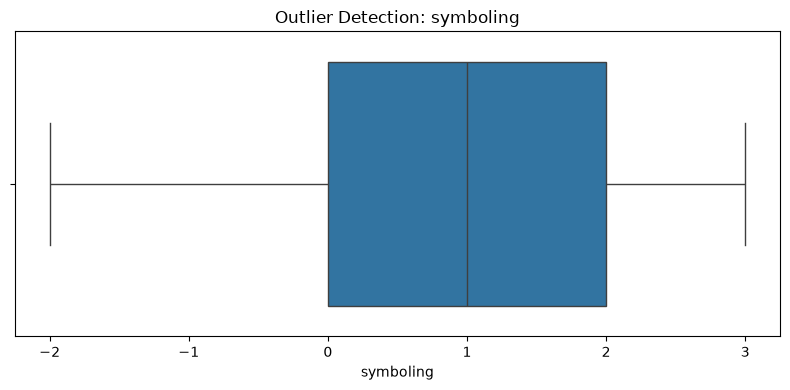

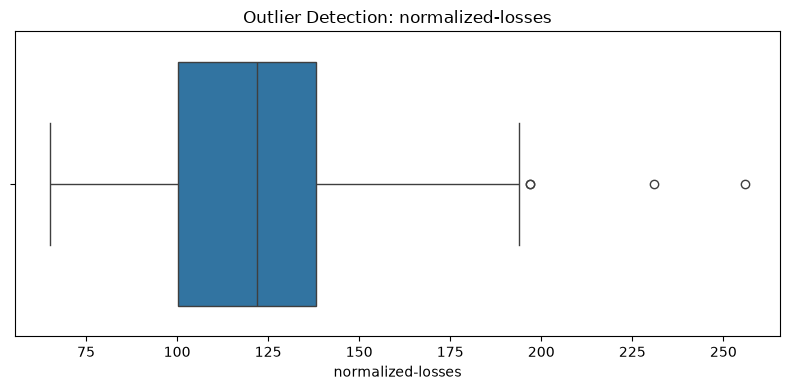

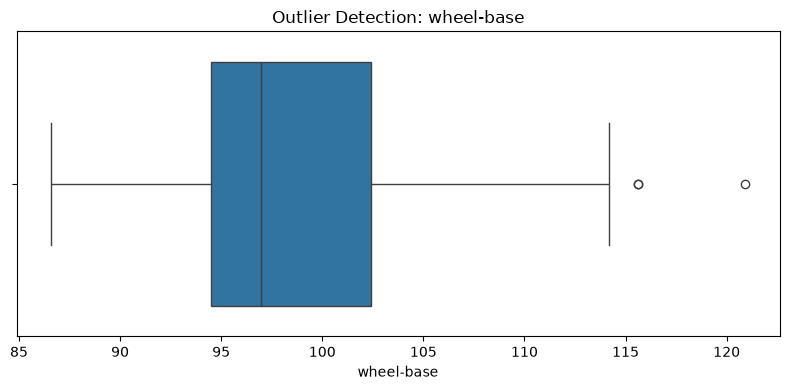

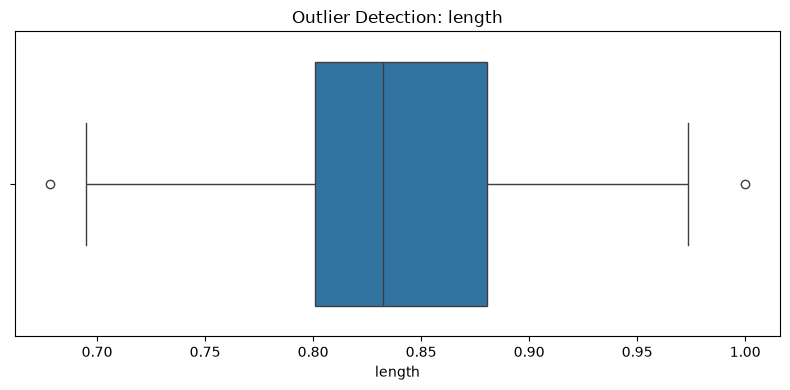

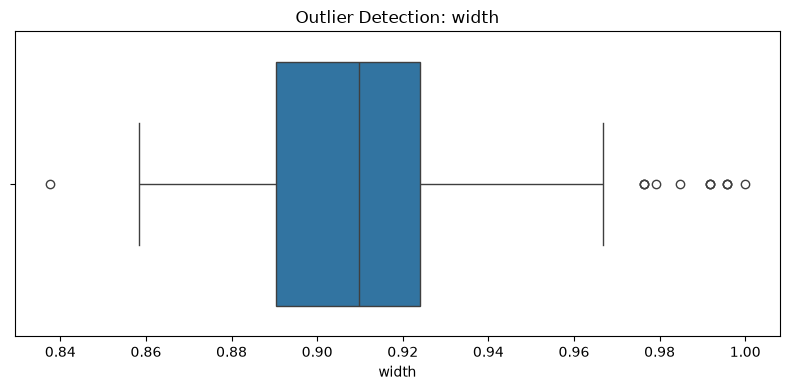

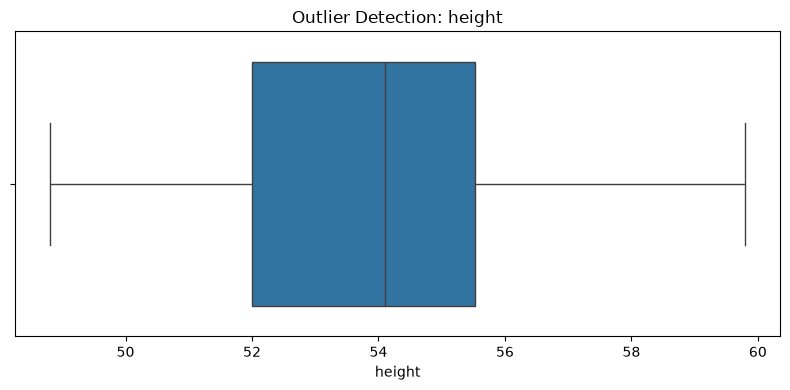

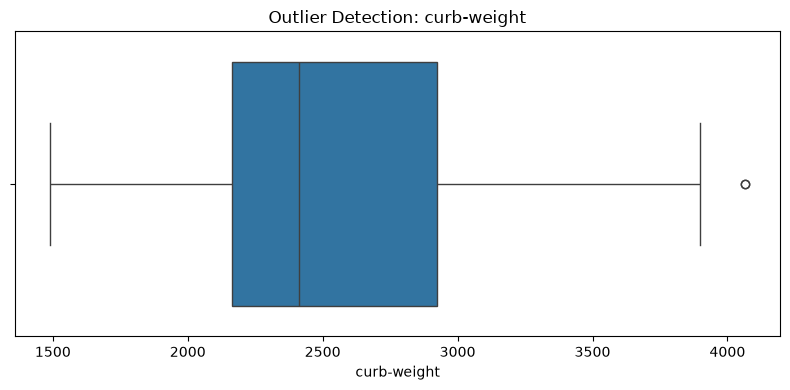

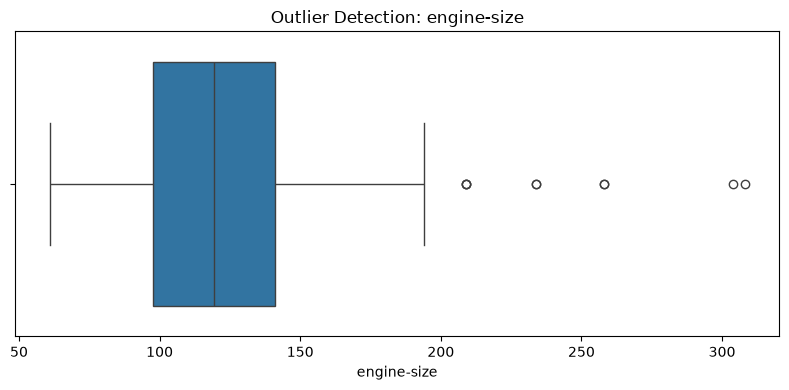

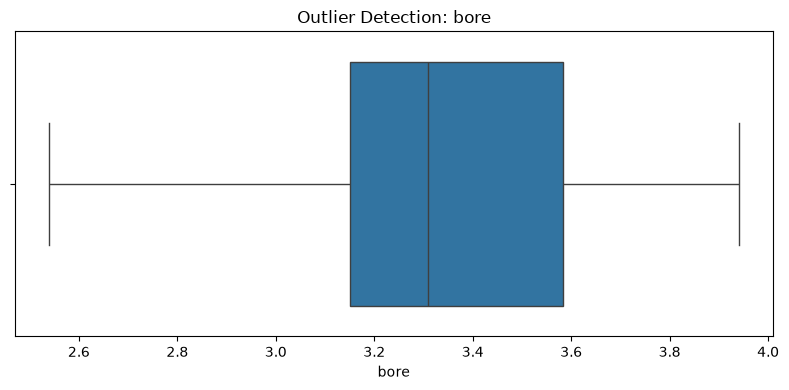

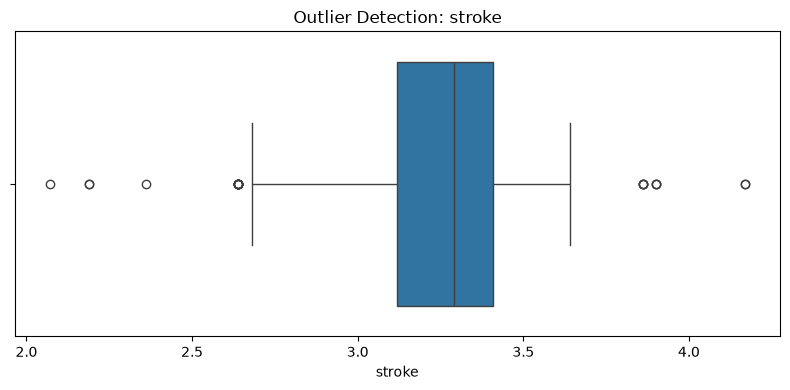

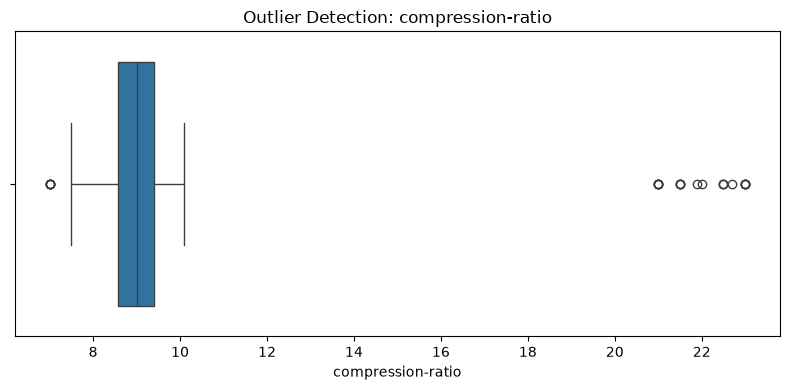

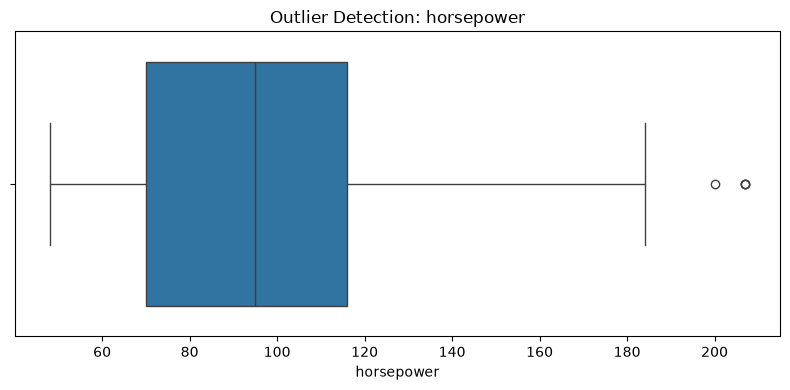

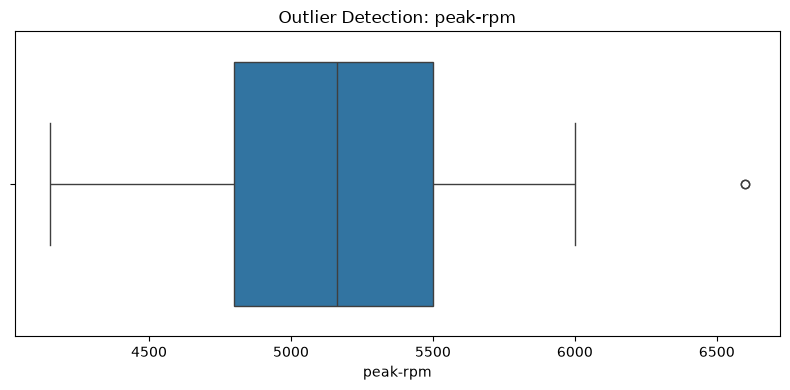

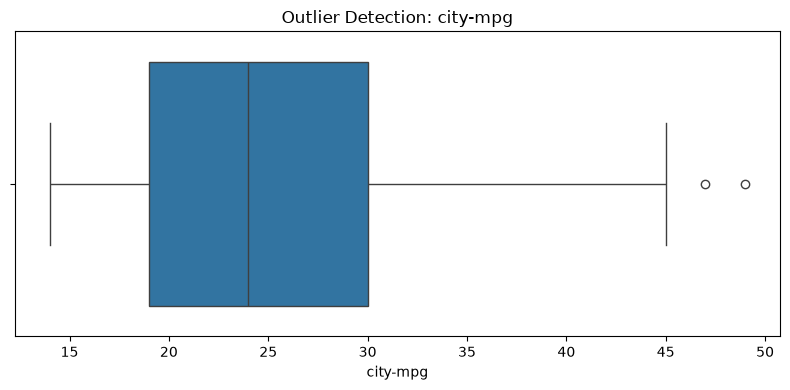

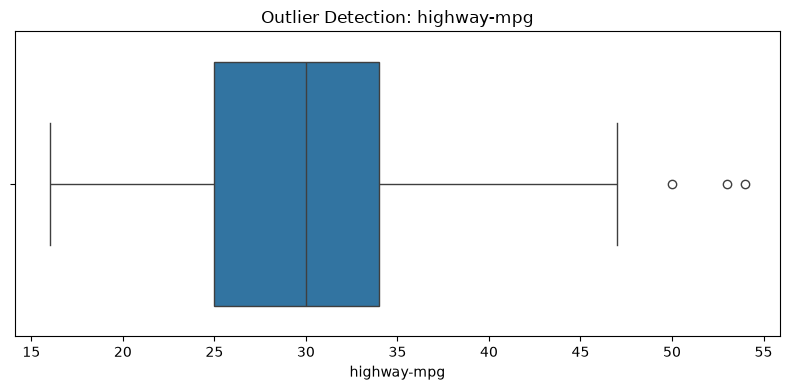

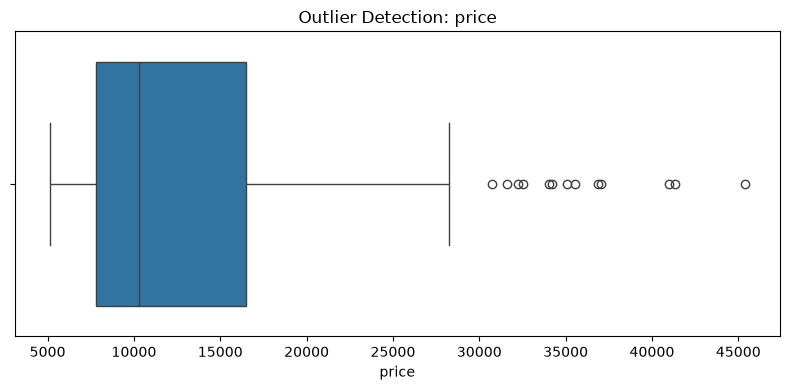

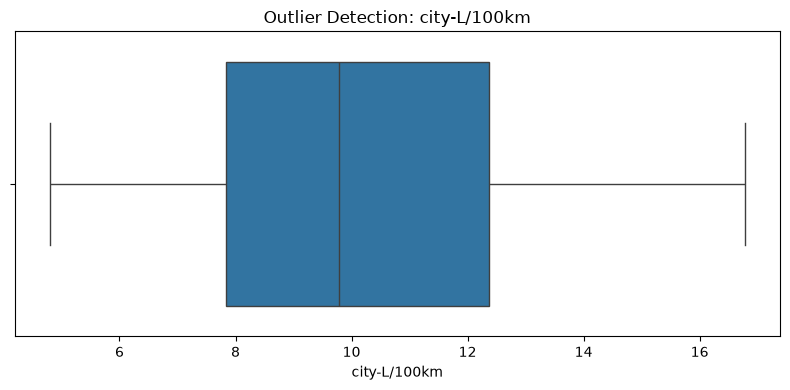

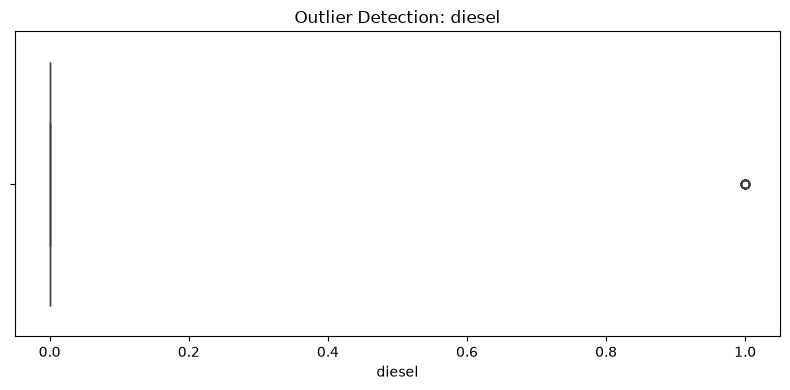

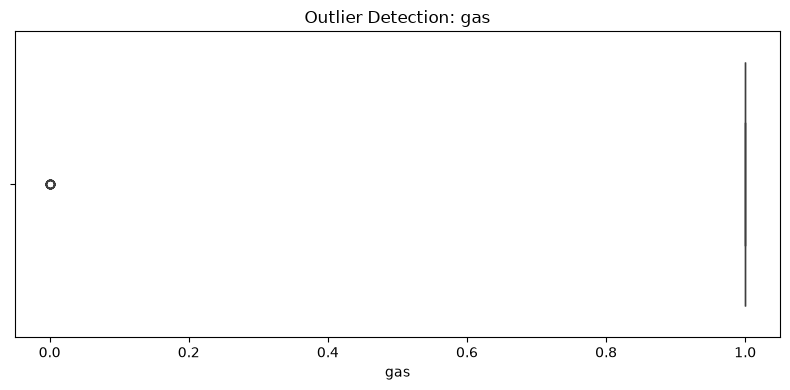

In [16]:
#HANDLING OUTLIERS
continuous_variables= automobile_clean[['symboling','normalized-losses','wheel-base','length','width','height','curb-weight','engine-size','bore','stroke',
    'compression-ratio','horsepower','peak-rpm','city-mpg','highway-mpg','price','city-L/100km','diesel','gas']]
for column in continuous_variables:
    Q1 = continuous_variables[column].quantile(0.25)
    Q3 = continuous_variables[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = automobile_clean[(automobile_clean[column] < lower_bound) |(automobile_clean[column] > upper_bound)]

    # Plot boxplot
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=continuous_variables[column])

    plt.title(f'Outlier Detection: {column}')
    plt.xlabel(column)
    plt.tight_layout()
    plt.show()

In [17]:
automobile_clean.to_csv("melody.csv")

In [18]:
automobile_final= pd.read_csv("melody.csv")

### DESCRIPTIVE STATISTICS

In [13]:
continuous_variables= automobile_final[['symboling','normalized-losses','wheel-base','length','width','height','curb-weight','engine-size','bore','stroke',
    'compression-ratio','horsepower','peak-rpm','city-mpg','highway-mpg','price','city-L/100km','diesel','gas']]

In [14]:
categorical_variables = automobile_final.columns.drop(continuous_variables)

In [15]:
print("\n mean\n")
print(continuous_variables. mean())
print("\n median \n")
print(continuous_variables. median())
print("\n mode \n")
print(continuous_variables. mode())


 mean

symboling                0.845000
normalized-losses      122.000000
wheel-base              98.781000
length                   0.836682
width                    0.914799
height                  53.796500
curb-weight           2548.695000
engine-size            125.880000
bore                     3.329645
stroke                   3.260235
compression-ratio       10.157600
horsepower             102.612562
peak-rpm              5118.253695
city-mpg                25.240000
highway-mpg             30.755000
price                13093.165000
city-L/100km             9.903482
diesel                   0.100000
gas                      0.900000
dtype: float64

 median 

symboling                1.000000
normalized-losses      122.000000
wheel-base              96.950000
length                   0.832292
width                    0.909722
height                  54.100000
curb-weight           2414.000000
engine-size            119.500000
bore                     3.310000
stroke        

In [16]:
#frequencies for categorical variables
for col in categorical_variables:
    print(automobile_final[col].value_counts())
    print("\n")


Unnamed: 0
0      1
1      1
2      1
3      1
4      1
      ..
196    1
197    1
198    1
199    1
200    1
Name: count, Length: 200, dtype: int64


make
toyota           32
nissan           18
mazda            17
honda            13
mitsubishi       13
subaru           12
volkswagen       12
peugot           11
volvo            11
dodge             9
bmw               8
mercedes-benz     8
plymouth          7
audi              6
saab              6
porsche           4
alfa-romero       3
chevrolet         3
isuzu             2
jaguar            2
renault           2
mercury           1
Name: count, dtype: int64


aspiration
std      164
turbo     36
Name: count, dtype: int64


num-of-doors
four    115
two      85
Name: count, dtype: int64


body-style
sedan          93
hatchback      68
wagon          25
hardtop         8
convertible     6
Name: count, dtype: int64


drive-wheels
fwd    118
rwd     74
4wd      8
Name: count, dtype: int64


engine-location
front    197
rear       3
N

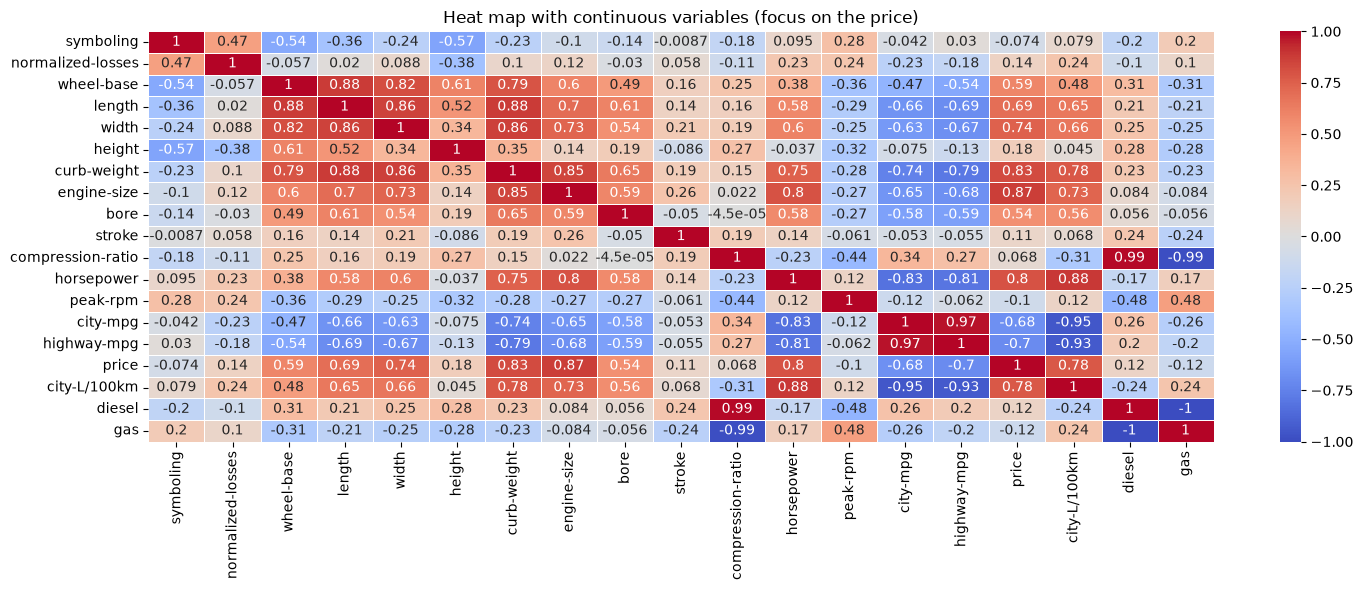

In [17]:
#heatmap showing the correlation coefficients of the continuous variables
plt.figure(figsize=(15,6))
corr_matrix= continuous_variables.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm',vmin=-1,vmax=1,linewidths=0.5)
plt.title('Heat map with continuous variables (focus on the price)')
plt.tight_layout()
plt.show()


In [18]:
#average price per categorical variable
categorical_variables = automobile_final[['drive-wheels','body-style','make','aspiration','num-of-doors','engine-location','engine-type',
    'num-of-cylinders','fuel-system','horsepower-binned']]
price= automobile_final['price']
cats_meanprice={}
for category in categorical_variables:
    cats_meanprice[category] = automobile_final.groupby(category)['price'].mean().to_dict()

print(cats_meanprice)

{'drive-wheels': {'4wd': 10241.0, 'fwd': 9244.77966101695, 'rwd': 19538.12162162162}, 'body-style': {'convertible': 21890.5, 'hardtop': 22208.5, 'hatchback': 9957.441176470587, 'sedan': 14228.139784946237, 'wagon': 12371.96}, 'make': {'alfa-romero': 15498.333333333334, 'audi': 17859.166666666668, 'bmw': 26118.75, 'chevrolet': 6007.0, 'dodge': 7875.444444444444, 'honda': 8184.692307692308, 'isuzu': 8916.5, 'jaguar': 33900.0, 'mazda': 10652.882352941177, 'mercedes-benz': 33647.0, 'mercury': 16503.0, 'mitsubishi': 9239.76923076923, 'nissan': 10415.666666666666, 'peugot': 15489.09090909091, 'plymouth': 7963.428571428572, 'porsche': 31400.5, 'renault': 9595.0, 'saab': 15223.333333333334, 'subaru': 8541.25, 'toyota': 9885.8125, 'volkswagen': 10077.5, 'volvo': 18063.18181818182}, 'aspiration': {'std': 12399.146341463415, 'turbo': 16254.805555555555}, 'num-of-doors': {'four': 13498.034782608696, 'two': 12545.4}, 'engine-location': {'front': 12766.7461928934, 'rear': 34528.0}, 'engine-type': {'

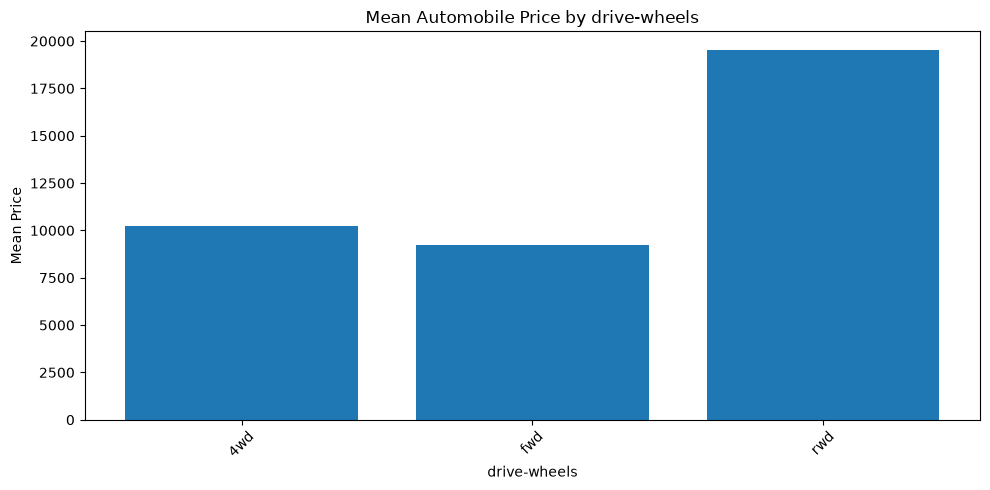

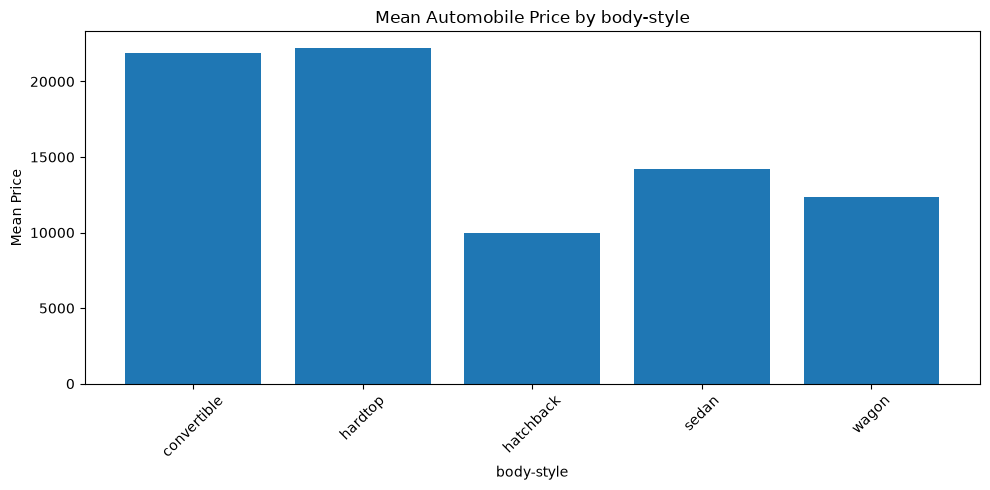

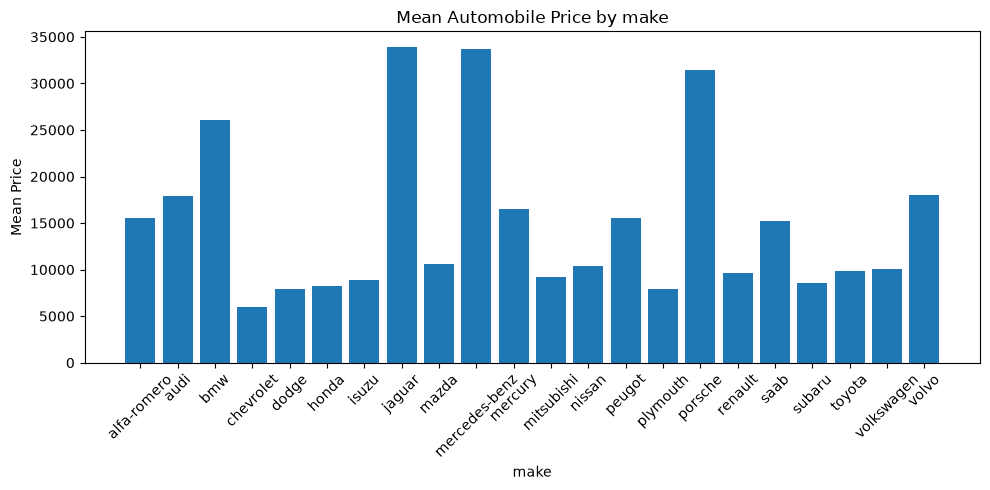

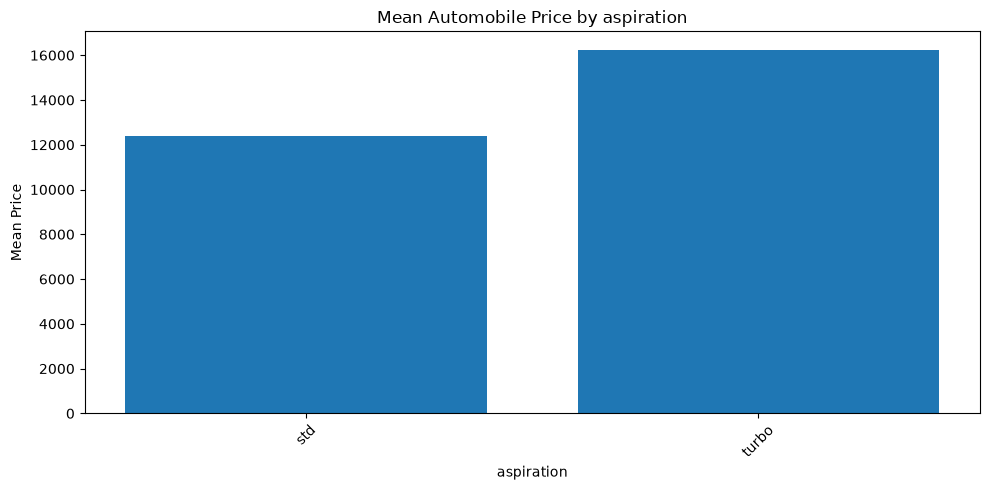

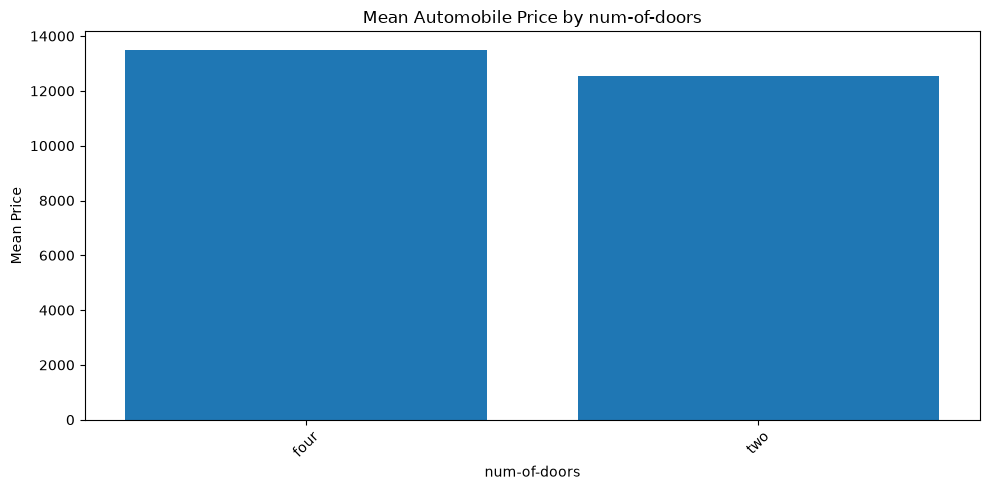

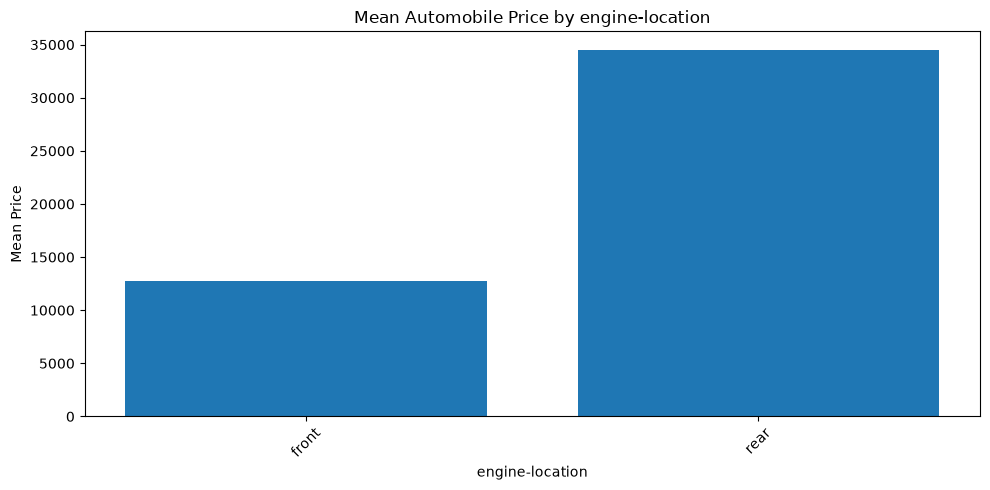

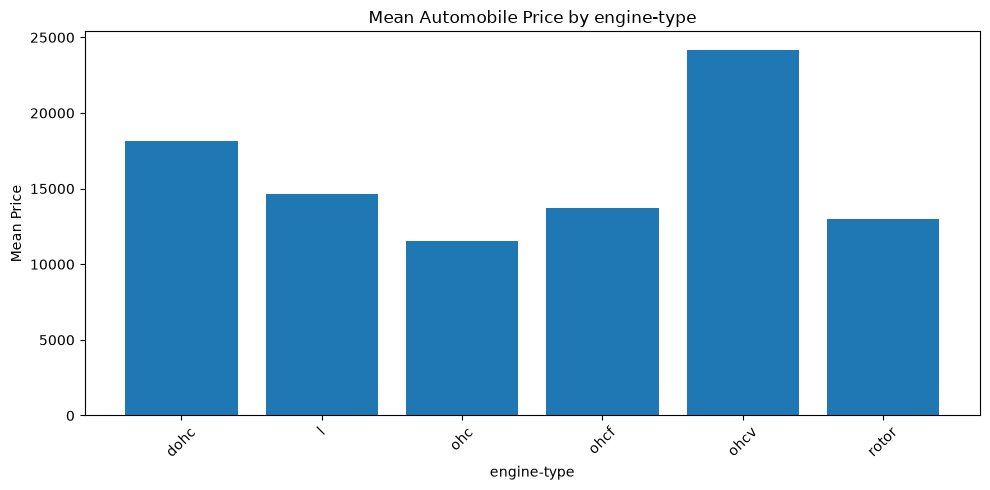

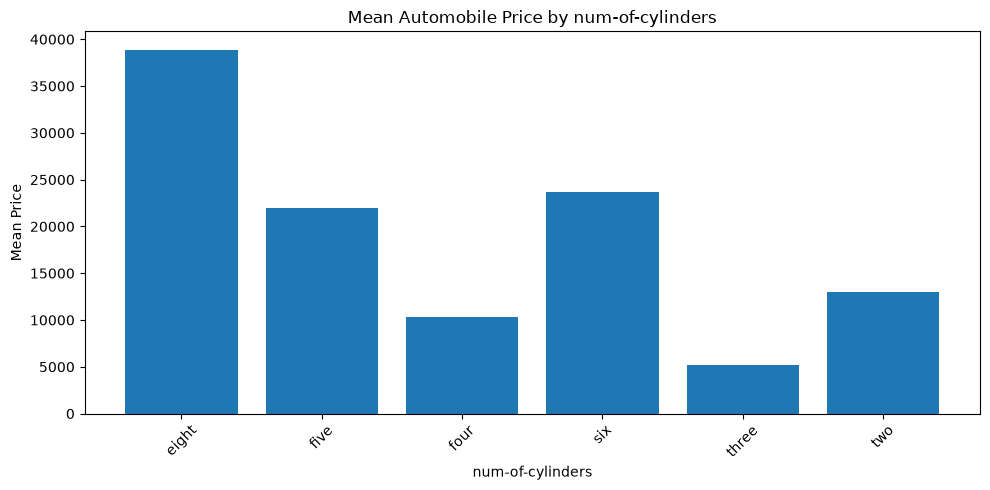

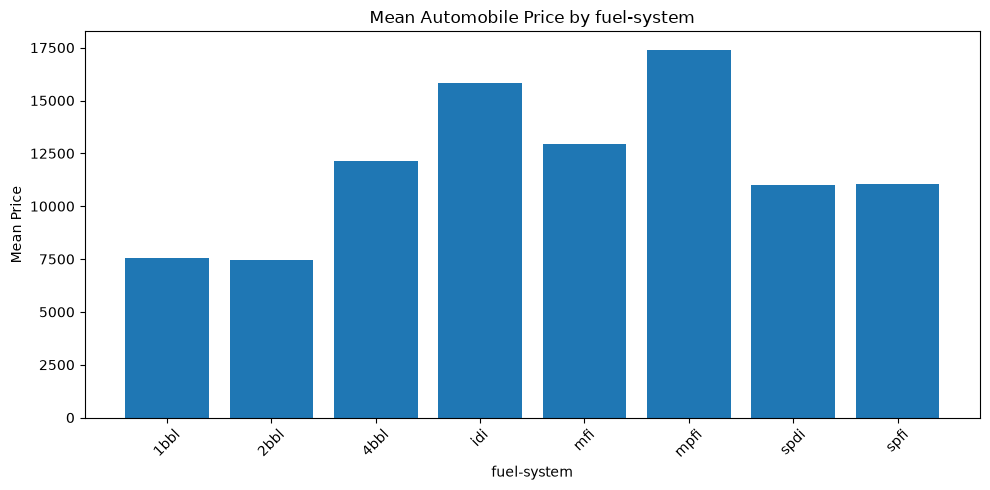

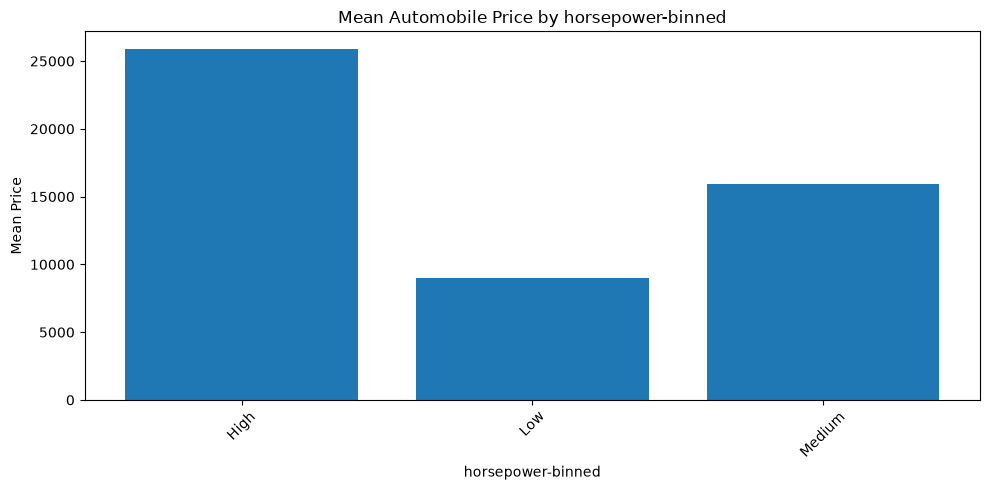

In [19]:
for category, subcategories in cats_meanprice.items():
    plt.figure(figsize=(10, 5))
    plt.bar(subcategories.keys(),subcategories.values())
    plt.title(f'Mean Automobile Price by {category}')
    plt.xlabel(category)
    plt.ylabel('Mean Price')

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

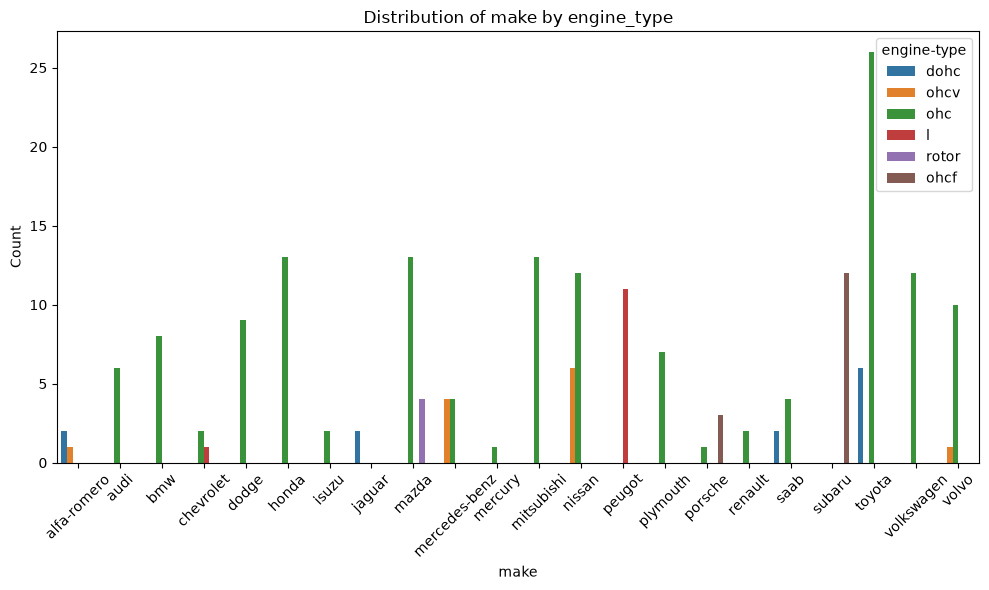

In [20]:
#TWO CATEGORICAL VARIABLES

plt.figure(figsize=(10, 6))
sns.countplot(data=automobile_final, x='make', hue='engine-type')
plt.title('Distribution of make by engine_type')
plt.xlabel('make')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend(title='engine-type')
plt.tight_layout()
plt.show()

#### FEATURE SELECTION WITH RECURSIVE FEATURE ELIMINATION

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import RFE

X = automobile_final.drop(columns=['price'])
y = automobile_final['price']

X_encoded = pd.get_dummies(X, columns= ['drive-wheels','body-style','make','aspiration','num-of-doors','engine-location','engine-type','num-of-cylinders',
                                       'fuel-system','horsepower-binned'], dtype=int)

X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

rfe_selector = RFE(estimator=model, n_features_to_select=4, step=1)

rfe_selector.fit(X_train, y_train)

ranking_df = pd.DataFrame({'Specification': X_encoded.columns,'Is_Top_Driver': rfe_selector.support_,  
    'RFE_Rank': rfe_selector.ranking_}).sort_values(by='RFE_Rank')

print(ranking_df.to_string(index=False))



--- CAR SPECIFICATION IMPACT RANKINGS ---
           Specification  Is_Top_Driver  RFE_Rank
              Unnamed: 0           True         1
             curb-weight           True         1
              horsepower           True         1
             engine-size           True         1
                   width          False         2
             highway-mpg          False         3
            city-L/100km          False         4
                peak-rpm          False         5
                make_bmw          False         6
                city-mpg          False         7
       normalized-losses          False         8
      body-style_hardtop          False         9
                    bore          False        10
              wheel-base          False        11
                  length          False        12
                  height          False        13
       compression-ratio          False        14
                  stroke          False        15
   num-o

 ## LINK TO GITHUB

In [ ]:
https://github.com/kayenymiriammelody/automobile